# Lab 3:ANN & Deep Learning
Artificial Neural Network, Forward and Backward Propagation


---

## Introduction

An Artificial Neural Network (ANN) learns to map inputs to outputs by repeatedly adjusting its internal parameters (weights and biases) so that its predictions get closer to the true target values. This laboratory walks through that learning process step by step, using only **NumPy**, so that the internal mechanics of an ANN are fully visible — nothing is hidden inside a deep learning framework.

By the end of this lab, you will have built, from first principles, every stage of the ANN learning cycle:

1. Input processing
2. Forward propagation
3. Loss / cost computation
4. Backward propagation
5. Gradient computation
6. Parameter updates
7. Iterative training
8. Model evaluation

Each stage is implemented as a small, reusable function, and later sections (training, evaluation, experiments, final task) simply call these functions rather than re-deriving the mathematics again.


## Learning Objectives

After completing this lab, students should be able to:

- Explain the basic architecture of an Artificial Neural Network.
- Understand neurons, weights, biases, and activation functions.
- Implement forward propagation manually.
- Calculate neuron activations using matrix operations.
- Understand and implement an appropriate loss function.
- Derive the basic idea of backpropagation.
- Calculate gradients of weights and biases.
- Update parameters using gradient descent.
- Train an ANN iteratively.
- Monitor the loss during training.
- Evaluate the trained ANN on unseen test data.
- Interpret the effect of learning rate and number of training iterations.
- Understand how ANN parameters change during learning.


<a id="section1"></a>
## 1. Packages and Setup

This lab uses only well-established scientific Python libraries:

- **NumPy** — vectorized matrix operations that implement the ANN itself (forward pass, backward pass, gradient descent).
- **Pandas** — organizing and inspecting the dataset in tabular form.
- **Matplotlib** — visualizing class distributions, loss curves, and the confusion matrix.
- **scikit-learn** — *only* for dataset loading, train/test splitting, feature scaling, and evaluation metrics. It is **not** used to build or train the neural network itself; that part is implemented manually with NumPy in later sections.

A fixed random seed is set once, here, so that dataset splitting, weight initialization, and all subsequent results are reproducible.


In [6]:
# Core numerical / data-handling libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# scikit-learn utilities: dataset, splitting, scaling, and evaluation metrics ONLY
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Fixed random seed for reproducibility across the whole notebook
RANDOM_SEED = 26
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")
print("Random seed set to:", RANDOM_SEED)


Libraries imported successfully.
Random seed set to: 26


<a id="section2"></a>
## 2. Dataset — Breast Cancer Wisconsin (Diagnostic) Dataset

This lab uses the **Breast Cancer Wisconsin Diagnostic dataset**, available directly through `sklearn.datasets.load_breast_cancer`. It is chosen because it:

- is lightweight and ships with scikit-learn (no external download needed),
- represents a real-world **binary classification** problem (malignant vs. benign tumor),
- contains purely numerical features, which is ideal for a matrix-based ANN,
- is small enough to train quickly on CPU inside Google Colab.

The task is: given 30 numeric features computed from a digitized image of a breast mass, predict whether the tumor is **malignant (0)** or **benign (1)**.


In [9]:
# Load the dataset from scikit-learn
breast_cancer = load_breast_cancer()

# Build a single Pandas DataFrame combining features and target for inspection
df = pd.DataFrame(breast_cancer.data, columns=breast_cancer.feature_names)
df["target"] = breast_cancer.target

print("Dataset shape (samples, columns including target):", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nFeature names:")
print(list(breast_cancer.feature_names))

print("\nTarget classes:", list(breast_cancer.target_names), "-> encoded as", sorted(df['target'].unique()))
print("Number of classes:", df["target"].nunique())

print("\nClass distribution (counts):")
print(df["target"].value_counts().rename(index={0: "malignant (0)", 1: "benign (1)"}))


Dataset shape (samples, columns including target): (569, 31)

First five rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Feature names:
[np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness'), np.str_('mean compactness'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('mean symmetry'), np.str_('mean fractal dimension'), np.str_('radius error'), np.str_('texture error'), np.str_('perimeter error'), np.str_('area error'), np.str_('smoothness error'), np.str_('compactness error'), np.str_('concavity error'), np.str_('concave points error'), np.str_('symmetry error'), np.str_('fractal dimension error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst smoothness'), np.str_('worst compactness'), np.str_('worst concavity'), np.str_('worst concave points'), np.str_('worst symmetry'), np.str_('worst fractal dimension')]

Target classes: [np.str_('malignant'), np.str_('benign')] -> encoded as [np.int64(0), np.int64(1)]
Number of classes: 2

Class distributi

<a id="section3"></a>
## 3. Data Exploration

Before building any model, it is good practice to briefly explore the dataset: its size, class balance, basic statistics, and whether any values are missing.


In [10]:
# Dataset dimensions
n_samples, n_features = breast_cancer.data.shape
print("Number of samples :", n_samples)
print("Number of features:", n_features)

# Basic descriptive statistics of the raw features
display(df.describe().T.head(10))  # showing first 10 features for brevity

# Missing-value check
missing_total = df.isnull().sum().sum()
print("\nTotal missing values in dataset:", missing_total)
print


Number of samples : 569
Number of features: 30


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744



Total missing values in dataset: 0


print outliers in mean area column.

In [16]:
q1=df['mean area'].quantile(0.10)
q3=df['mean area'].quantile(0.90)
iqr=q3-q1
lower= q1-1.5*iqr
upper=q3+1.5*iqr
outliers=df[(df['mean area']<lower) | (df['mean area']>upper)]
print(outliers['mean area'])
print(len(outliers))



212    2499.0
461    2501.0
Name: mean area, dtype: float64
2


In [20]:
df1=df[(df['mean area']>=lower) & (df['mean area']<=upper)]
print(f"Cleaned dataset:{df1.shape[0]}")



Cleaned dataset:567


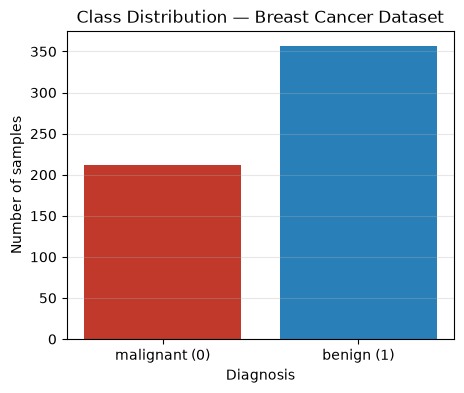

In [22]:
# Visualization: class distribution
class_counts = df["target"].value_counts().sort_index()
class_labels = ["malignant (0)", "benign (1)"]

plt.figure(figsize=(5, 4))
plt.bar(class_labels, class_counts.values, color=["#c0392b", "#2980b9"])
plt.title("Class Distribution — Breast Cancer Dataset")
plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.grid(axis="y", alpha=0.3)
plt.show()


<a id="section4"></a>
## 4. Data Preprocessing

Neural networks are sensitive to the **scale** of input features. Features such as `mean area` (hundreds to thousands) and `mean smoothness` (small decimals) live on very different numeric scales. Without scaling, large-magnitude features would dominate the weighted sums computed inside the network, and gradient descent would converge slowly or unstably.

The preprocessing pipeline is:

1. **Separate** features (`X`) from the target (`y`).
2. **Split** the data into training and test sets, so the model is evaluated on unseen data.
3. **Standardize** the features (zero mean, unit variance) — the scaler is **fit only on the training data**, then used to transform both the training and test sets, to avoid leaking information from the test set.

Finally, the target vectors are reshaped into column vectors of shape `(m, 1)`, matching the convention used throughout the forward/backward propagation equations, where `m` is the number of examples.


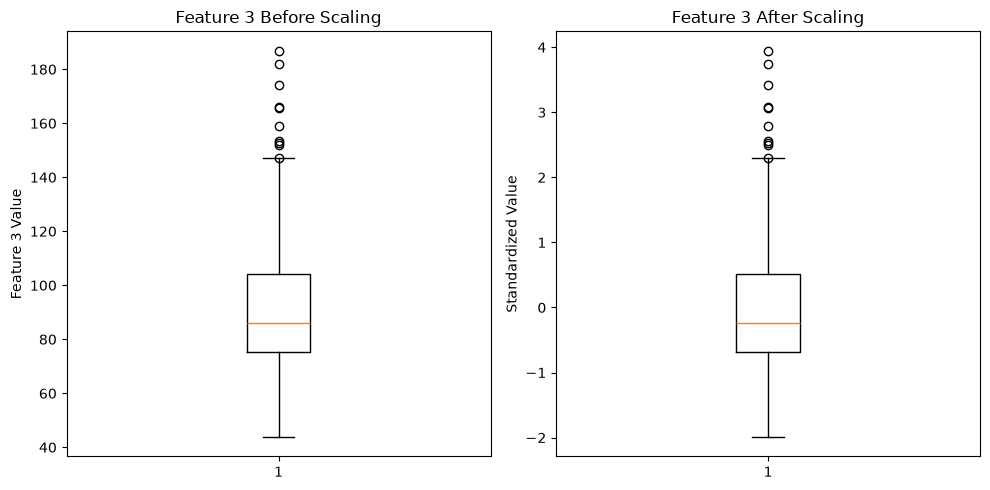

X_train shape: (455, 30)
X_test shape : (114, 30)
y_train shape: (455, 1)
y_test shape : (114, 1)


In [39]:
# 1. Separate features and target
X = breast_cancer.data              # shape (n_samples, n_features)
y = breast_cancer.target            # shape (n_samples,)

# 2. Train-test split (80% train, 20% test), stratified to preserve class balance
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# 3. Feature standardization: fit ONLY on training data, then transform both sets
scaler = StandardScaler()
#plot train data before and after scaling...so plot X_train_raw and X_train after scaling

X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.boxplot(X_train_raw[:, 2])
plt.title("Feature 3 Before Scaling")
plt.ylabel("Feature 3 Value")

plt.subplot(1, 2, 2)
plt.boxplot(X_train[:, 2])
plt.title("Feature 3 After Scaling")
plt.ylabel("Standardized Value")

plt.tight_layout()
plt.show()

# Reshape targets into column vectors (m, 1) to match the ANN's matrix conventions
y_train = y_train_raw.reshape(-1, 1).astype(float)
y_test = y_test_raw.reshape(-1, 1).astype(float)

print("X_train shape:", X_train.shape)  # (m_train, n_features)
print("X_test shape :", X_test.shape)   # (m_test, n_features)
print("y_train shape:", y_train.shape)  # (m_train, 1)
print("y_test shape :", y_test.shape)   # (m_test, 1)


In [40]:
# Split training data into 90% train and 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,test_size=0.1,random_state=RANDOM_SEED,stratify=y_train)

print("X_train shape:", X_train.shape)
print("X_val shape  :", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape  :", y_val.shape)


X_train shape: (409, 30)
X_val shape  : (46, 30)
y_train shape: (409, 1)
y_val shape  : (46, 1)


<a id="section5"></a>
## 5. ANN Architecture

It implements a simple, fully-connected ANN with **one hidden layer**:

```
Input (30 features) --> Dense(16) --> ReLU --> Dense(1) --> Sigmoid --> Output (probability)
```

| Layer   | Neurons | Activation |
|---------|---------|------------|
| Input   | 30 (number of features) | — |
| Hidden  | 16                       | ReLU |
| Output  | 1                        | Sigmoid |

**Key components:**

- **Weights (`W1`, `W2`)** — matrices whose entries are learned; they control how strongly each input/neuron influences the next layer.
- **Biases (`b1`, `b2`)** — per-neuron offsets that shift the weighted sum before the activation function is applied.
- **ReLU** — a non-linear activation used in the hidden layer, allowing the network to model non-linear relationships.
- **Sigmoid** — squashes the final output into the range `(0, 1)`, interpreted as the probability of the "benign" class, suitable for **binary classification**.

Mathematically, for an input matrix `X` of shape `(m, n_x)`:

$$Z^{[1]} = X W^{[1]} + b^{[1]}, \qquad A^{[1]} = \text{ReLU}(Z^{[1]})$$
$$Z^{[2]} = A^{[1]} W^{[2]} + b^{[2]}, \qquad A^{[2]} = \sigma(Z^{[2]})$$

where `m` is the number of examples, `n_x = 30` is the number of input features, and `A^{[2]}` is the predicted probability for each example.


<a id="section6"></a>
## 6. Activation Functions

### Sigmoid

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

The sigmoid function maps any real number into the range `[0, 1]`, which makes it a natural choice for the output layer of a binary classifier: the output can be directly interpreted as a probability.

### ReLU (Rectified Linear Unit)

$$\text{ReLU}(z) = \max(0, z)$$

ReLU is widely used in hidden layers because it is computationally cheap, introduces non-linearity (allowing the network to learn complex patterns), and helps mitigate the vanishing-gradient problem that affects saturating activations like sigmoid when used in deep hidden layers.

The cell below implements both activations and their derivatives (needed later for backpropagation), and briefly tests them on a small example.


In [41]:
def sigmoid(z):
    '''Sigmoid activation: maps input to the range (0, 1).'''
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative(z):
    '''Derivative of sigmoid with respect to z, evaluated at z.'''
    s = sigmoid(z)
    return s * (1 - s)

def relu(z):
    '''ReLU activation: element-wise max(0, z).'''
    return np.maximum(0, z)

def relu_derivative(z):
    '''Derivative of ReLU with respect to z: 1 where z > 0, else 0.'''
    return (z > 0).astype(float)

# Quick sanity test on a small example
z_test = np.array([-2.0, -0.5, 0.0, 0.5, 2.0])
print("z            :", z_test)
print("sigmoid(z)   :", np.round(sigmoid(z_test), 4))
print("sigmoid'(z)  :", np.round(sigmoid_derivative(z_test), 4))
print("relu(z)      :", relu(z_test))
print("relu'(z)     :", relu_derivative(z_test))


z            : [-2.  -0.5  0.   0.5  2. ]
sigmoid(z)   : [0.1192 0.3775 0.5    0.6225 0.8808]
sigmoid'(z)  : [0.105 0.235 0.25  0.235 0.105]
relu(z)      : [0.  0.  0.  0.5 2. ]
relu'(z)     : [0. 0. 0. 1. 1.]


In [44]:
def sigmoid(z):
    '''Sigmoid activation: maps input to the range (0, 1).'''
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_derivative(z):
    '''Derivative of sigmoid with respect to z, evaluated at z.'''
    s = sigmoid(z)
    return s * (1 - s)

def relu(z):
    '''ReLU activation: element-wise max(0, z).'''
    return np.maximum(0, z)

def relu_derivative(z):
    '''Derivative of ReLU with respect to z: 1 where z > 0, else 0.'''
    return (z > 0).astype(float)

# Quick sanity test on a small example
z_test = np.array([-2.0, -0.5, 27.0, 10.0, 2.0])
print("z            :", z_test)
print("sigmoid(z)   :", np.round(sigmoid(z_test), 4))
print("sigmoid'(z)  :", np.round(sigmoid_derivative(z_test), 4))
print("relu(z)      :", relu(z_test))
print("relu'(z)     :", relu_derivative(z_test))


z            : [-2.  -0.5 27.  10.   2. ]
sigmoid(z)   : [0.1192 0.3775 1.     1.     0.8808]
sigmoid'(z)  : [0.105 0.235 0.    0.    0.105]
relu(z)      : [ 0.  0. 27. 10.  2.]
relu'(z)     : [0. 0. 1. 1. 1.]


###

**Task:** Implement the **tanh** activation function and its derivative, then test them on the same `z_test` array used above.

$$\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}, \qquad \tanh'(z) = 1 - \tanh(z)^2$$




In [46]:
def tanh_activation(z):
    '''TODO: return tanh(z) element-wise.'''
    # write your cod
    result = (np.exp(z)- np.exp(-z))/(np.exp(z)+ np.exp(-z))   
    
    return result

def tanh_derivative(z):
    '''TODO: return the derivative of tanh, evaluated at z.'''
    # write your code here
    result = 1- (tanh_activation(z)*tanh_activation(z))
    
    return result

# Once implemented, uncomment the lines below to check your results
print("z            :", z_test)
print("tanh(z)  :", np.round(tanh_activation(z_test), 4))
print("tanh'(z) :", np.round(tanh_derivative(z_test), 4))


z            : [-2.  -0.5 27.  10.   2. ]
tanh(z)  : [-0.964  -0.4621  1.      1.      0.964 ]
tanh'(z) : [0.0707 0.7864 0.     0.     0.0707]


In [47]:
#gpt
def tanh_activation(z):
    '''TODO: return tanh(z) element-wise.'''
    result = np.tanh(z)
    return result


def tanh_derivative(z):
    '''TODO: return the derivative of tanh, evaluated at z.'''
    result = 1 - np.tanh(z) ** 2
    return result


# Once implemented, uncomment the lines below to check your results
print("z            :", z_test)
print("tanh(z)  :", np.round(tanh_activation(z_test), 4))
print("tanh'(z) :", np.round(tanh_derivative(z_test), 4))

z            : [-2.  -0.5 27.  10.   2. ]
tanh(z)  : [-0.964  -0.4621  1.      1.      0.964 ]
tanh'(z) : [0.0707 0.7864 0.     0.     0.0707]


<a id="section7"></a>
## 7. Parameter Initialization

Before training can begin, the network's parameters must be initialized:

- **`W1`** — shape `(n_x, n_h)` — weights connecting the input layer to the hidden layer.
- **`b1`** — shape `(1, n_h)` — biases for the hidden layer.
- **`W2`** — shape `(n_h, n_y)` — weights connecting the hidden layer to the output layer.
- **`b2`** — shape `(1, n_y)` — bias for the output layer.

where `n_x` is the number of input features, `n_h` is the number of hidden neurons, and `n_y` is the number of output neurons (`1` for binary classification).

Weights are initialized with small random values (to break symmetry between neurons), and biases are initialized to zero, which is a standard and safe choice for bias terms.


In [57]:
def initialize_parameters(n_x, n_h, n_y):
    '''
    Initialize weights and biases for a 2-layer ANN.

    Arguments:
    n_x -- size of the input layer (number of features)
    n_h -- size of the hidden layer (number of hidden neurons)
    n_y -- size of the output layer (number of output neurons)

    Returns:
    parameters -- dict containing W1, b1, W2, b2
    '''
    W1 = np.random.randn(n_x, n_h) * 0.01   # shape (n_x, n_h)
    b1 = np.zeros((1, n_h))                 # shape (1, n_h)
    W2 = np.random.randn(n_h, n_y) * 0.01   # shape (n_h, n_y)
    b2 = np.zeros((1, n_y))                 # shape (1, n_y)

    parameters = {"W1": W1, "b1": b1, "W2": W2, "b2": b2}
    return parameters

# Architecture sizes
n_x = X_train.shape[1]  # number of input features
n_h = 16                 # number of hidden neurons
n_y = 1                  # single output neuron (binary classification)

parameters = initialize_parameters(n_x, n_h, n_y)

for name, value in parameters.items():
    print(f"{name} shape: {value.shape}")


W1 shape: (30, 16)
b1 shape: (1, 16)
W2 shape: (16, 1)
b2 shape: (1, 1)




**Task:** Write a function `count_parameters(parameters)` that returns the **total number of trainable scalar values** in the network (the combined size of `W1`, `b1`, `W2`, and `b2`). This is a common way to report a model's size.




In [58]:
def count_parameters(parameters):
    '''
    TODO: Complete this function.
    Return the total number of trainable scalar values across
    W1, b1, W2, and b2 (i.e. the sum of parameters[name].size for each).
    '''
    # write your code here
    total_params = sum(param.size for param in parameters.values())
    return total_params

# Once implemented, uncomment the line below to check your result
print("Total trainable parameters:", count_parameters(parameters))


Total trainable parameters: 513


<a id="section8"></a>
## 8. Forward Propagation

Forward propagation computes the network's prediction for a batch of inputs `X`, given the current parameters. For our 2-layer ANN:

$$Z^{[1]} = X W^{[1]} + b^{[1]}$$
$$A^{[1]} = \text{ReLU}(Z^{[1]})$$
$$Z^{[2]} = A^{[1]} W^{[2]} + b^{[2]}$$
$$A^{[2]} = \sigma(Z^{[2]})$$

`A^{[2]}` is the predicted probability that a given example belongs to the "benign" class. All intermediate values (`Z1`, `A1`, `Z2`, `A2`) are stored in a **cache**, because they are needed again during backpropagation.


In [59]:
def forward_propagation(X, parameters):
    '''
    Perform one forward pass through the 2-layer ANN.

    Arguments:
    X -- input data, shape (m, n_x)
    parameters -- dict with W1, b1, W2, b2

    Returns:
    A2 -- predicted probabilities, shape (m, 1)
    cache -- dict with Z1, A1, Z2, A2 (needed for backpropagation)
    '''
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]

    Z1 = X.dot(W1) + b1          # shape (m, n_h)
    A1 = relu(Z1)                # shape (m, n_h)
    Z2 = A1.dot(W2) + b2         # shape (m, n_y)
    A2 = sigmoid(Z2)             # shape (m, n_y) -- predicted probabilities

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

# Quick test using the (still randomly initialized) parameters
A2_test, cache_test = forward_propagation(X_train, parameters)

print("Z1 shape:", cache_test["Z1"].shape)
print("A1 shape:", cache_test["A1"].shape)
print("Z2 shape:", cache_test["Z2"].shape)
print("A2 shape:", cache_test["A2"].shape)
print("\nFirst 5 predicted probabilities (before training):")
print(A2_test[:5].ravel())


Z1 shape: (409, 16)
A1 shape: (409, 16)
Z2 shape: (409, 1)
A2 shape: (409, 1)

First 5 predicted probabilities (before training):
[0.50033169 0.4997893  0.49929966 0.50033397 0.49983971]


In [62]:
def forward_propagation(X, parameters):
    '''
    Perform one forward pass through the 2-layer ANN.

    Arguments:
    X -- input data, shape (m, n_x)
    parameters -- dict with W1, b1, W2, b2

    Returns:
    A2 -- predicted probabilities, shape (m, 1)
    cache -- dict with Z1, A1, Z2, A2 (needed for backpropagation)
    '''
    W1, b1 = parameters["W1"], parameters["b1"]
    W2, b2 = parameters["W2"], parameters["b2"]

    Z1 = X.dot(W1) + b1          # shape (m, n_h)
    A1 = tanh_activation(Z1)                # shape (m, n_h)
    Z2 = A1.dot(W2) + b2         # shape (m, n_y)
    A2 = sigmoid(Z2)             # shape (m, n_y) -- predicted probabilities

    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2}
    return A2, cache

# Quick test using the (still randomly initialized) parameters
A2_test, cache_test = forward_propagation(X_train, parameters)

print("Z1 shape:", cache_test["Z1"].shape)
print("A1 shape:", cache_test["A1"].shape)
print("Z2 shape:", cache_test["Z2"].shape)
print("A2 shape:", cache_test["A2"].shape)
print("\nFirst 5 predicted probabilities (before training):")
print(A2_test[:5].ravel())


Z1 shape: (409, 16)
A1 shape: (409, 16)
Z2 shape: (409, 1)
A2 shape: (409, 1)

First 5 predicted probabilities (before training):
[0.50036495 0.49947004 0.49872953 0.50006477 0.49944227]




**Task:** ReLU units that never activate (output 0 for every example) are sometimes called "dead" neurons. Using `cache_test["A1"]` from the forward-propagation test above, compute **what fraction of the 16 hidden neurons are exactly zero for every training example**.




In [ ]:
def fraction_dead_relu_units(A1):
    '''
    TODO: Complete this function.
    A1 has shape (m, n_h). A hidden unit (column) is considered "dead"
    if it is exactly 0 for every one of the m examples.
    Return the fraction of hidden units that are dead (a float between 0 and 1).
    '''
    # write your code here
    fraction_dead = None
    return fraction_dead

# Once implemented, uncomment the line below to check your result
# print("Fraction of dead ReLU units:", fraction_dead_relu_units(cache_test["A1"]))


<a id="section9"></a>
## 9. Loss / Cost Function — Binary Cross-Entropy

A loss function quantifies how far the network's predictions are from the true labels. For binary classification, the standard choice is **binary cross-entropy**:

$$J = -\frac{1}{m} \sum_{i=1}^{m} \Big[ y^{(i)} \log(a^{(i)}) + (1 - y^{(i)}) \log(1 - a^{(i)}) \Big]$$

- Lower loss generally indicates predictions closer to the true labels.
- The loss is what backpropagation differentiates with respect to the parameters — it defines the direction and magnitude of every parameter update.
- A small epsilon is added inside the logarithms to avoid numerical issues (`log(0)`) when a prediction is extremely close to 0 or 1.


In [63]:
def compute_loss(y, y_hat, epsilon=1e-8):
    '''
    Compute binary cross-entropy loss.

    Arguments:
    y     -- true labels, shape (m, 1)
    y_hat -- predicted probabilities, shape (m, 1)
    epsilon -- small constant for numerical stability

    Returns:
    loss -- scalar binary cross-entropy loss
    '''
    m = y.shape[0]
    y_hat_clipped = np.clip(y_hat, epsilon, 1 - epsilon)  # avoid log(0)
    loss = -np.sum(y * np.log(y_hat_clipped) + (1 - y) * np.log(1 - y_hat_clipped)) / m
    return loss

# Test the loss function using the untrained model's predictions
initial_loss = compute_loss(y_train, A2_test)
print("Initial loss (before training):", initial_loss)


Initial loss (before training): 0.6936189012296642



**Task:** A trivial "baseline" classifier that always predicts a probability of `0.5` for every example acts as a useful reference point. Using `compute_loss`, calculate the loss this baseline would achieve on `y_train`, and compare it to the `initial_loss` printed above (from the randomly initialized network).



In [ ]:
def baseline_loss(y):
    '''
    TODO: Complete this function.
    Build an array of predictions the same shape as y, where every
    predicted probability is 0.5, then return compute_loss(y, predictions).
    '''
    # write your code here
    loss_value = None
    return loss_value

# Once implemented, uncomment the line below to compare with initial_loss
# print("Baseline (always 0.5) loss:", baseline_loss(y_train))


<a id="section10"></a>
## 10. Backward Propagation

Backward propagation applies the **chain rule** to compute how much each parameter (`W1`, `b1`, `W2`, `b2`) contributed to the final loss. These gradients tell gradient descent which direction to move each parameter in order to reduce the loss.

**Output layer:**
$$dZ^{[2]} = A^{[2]} - Y$$
$$dW^{[2]} = \frac{1}{m} (A^{[1]})^T dZ^{[2]}$$
$$db^{[2]} = \frac{1}{m} \sum dZ^{[2]}$$

**Hidden layer** (gradient flows backward through `W2`, then through the ReLU derivative):
$$dA^{[1]} = dZ^{[2]} (W^{[2]})^T$$
$$dZ^{[1]} = dA^{[1]} * \text{ReLU}'(Z^{[1]})$$
$$dW^{[1]} = \frac{1}{m} X^T dZ^{[1]}$$
$$db^{[1]} = \frac{1}{m} \sum dZ^{[1]}$$

Conceptually, the error at the output is first computed directly (`dZ2 = A2 - Y`, a convenient simplification that results from combining the sigmoid activation with cross-entropy loss). This error is then propagated backward: the output-layer gradients are computed first, the error is passed back through `W2` to the hidden layer, adjusted by the ReLU derivative (since ReLU is not active where `Z1 <= 0`), and finally used to compute the hidden-layer gradients.


In [64]:
def backward_propagation(X, Y, parameters, cache):
    '''
    Perform backpropagation to compute gradients of the loss
    with respect to W1, b1, W2, b2.

    Arguments:
    X -- input data, shape (m, n_x)
    Y -- true labels, shape (m, 1)
    parameters -- dict with W1, b1, W2, b2
    cache -- dict with Z1, A1, Z2, A2 from forward_propagation

    Returns:
    gradients -- dict with dW1, db1, dW2, db2
    '''
    m = X.shape[0]
    W2 = parameters["W2"]
    A1, Z1, A2 = cache["A1"], cache["Z1"], cache["A2"]

    # Output layer gradients
    dZ2 = A2 - Y                                  # shape (m, n_y)
    dW2 = A1.T.dot(dZ2) / m                       # shape (n_h, n_y)
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m  # shape (1, n_y)

    # Hidden layer gradients
    dA1 = dZ2.dot(W2.T)                           # shape (m, n_h)
    dZ1 = dA1 * relu_derivative(Z1)               # shape (m, n_h)
    dW1 = X.T.dot(dZ1) / m                        # shape (n_x, n_h)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m  # shape (1, n_h)

    gradients = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2}
    return gradients

# Test backpropagation using the forward-pass cache computed earlier
gradients_test = backward_propagation(X_train, y_train, parameters, cache_test)

for name, value in gradients_test.items():
    print(f"{name} shape: {value.shape}")


dW1 shape: (30, 16)
db1 shape: (1, 16)
dW2 shape: (16, 1)
db2 shape: (1, 1)


<a id="section11"></a>
## 11. Parameter Update — Gradient Descent

Once gradients are known, each parameter is updated by taking a small step in the direction that reduces the loss:

$$W := W - \alpha \, dW$$
$$b := b - \alpha \, db$$

where `α` (alpha) is the **learning rate**, controlling the size of each update step. This is implemented directly with NumPy — no external optimizer library is used — so the mechanics of gradient descent remain fully visible.


In [70]:
def update_parameters(parameters, gradients, learning_rate):
    '''
    Update parameters using vanilla gradient descent.

    Arguments:
    parameters -- dict with W1, b1, W2, b2
    gradients -- dict with dW1, db1, dW2, db2
    learning_rate -- step size (alpha)

    Returns:
    parameters -- dict with updated W1, b1, W2, b2
    '''
    print(parameters["W1"])
    print(parameters["b1"])
    print(parameters["W2"])
    print(parameters["b2"])
        
    parameters["W1"] = parameters["W1"] - learning_rate * gradients["dW1"]
    parameters["b1"] = parameters["b1"] - learning_rate * gradients["db1"]
    parameters["W2"] = parameters["W2"] - learning_rate * gradients["dW2"]
    parameters["b2"] = parameters["b2"] - learning_rate * gradients["db2"]
    return parameters

print("update_parameters() defined. It will be used inside the training loop.")


update_parameters() defined. It will be used inside the training loop.


<a id="section12"></a>
## 12. Complete Training Function

Training an ANN means repeating the following cycle many times:

1. Forward propagation → predictions
2. Compute the loss
3. Backward propagation → gradients
4. Update parameters using gradient descent
5. Repeat for a fixed number of iterations

The function below wires together the functions already defined above (`initialize_parameters`, `forward_propagation`, `compute_loss`, `backward_propagation`, `update_parameters`) — none of their logic is duplicated here.


In [71]:
def train_ann(X, Y, n_h, learning_rate=0.01, num_iterations=1000, print_loss=True):
    '''
    Train a 2-layer ANN (Input -> Dense(n_h) -> ReLU -> Dense(1) -> Sigmoid)
    using manually implemented forward/backward propagation and gradient descent.

    Arguments:
    X -- training features, shape (m, n_x)
    Y -- training labels, shape (m, 1)
    n_h -- number of hidden neurons
    learning_rate -- gradient descent step size (alpha)
    num_iterations -- number of training iterations
    print_loss -- whether to print loss periodically

    Returns:
    parameters -- learned parameters (W1, b1, W2, b2)
    loss_history -- list of loss values recorded during training
    '''
    n_x = X.shape[1]
    n_y = Y.shape[1]

    parameters = initialize_parameters(n_x, n_h, n_y)
    loss_history = []

    for i in range(num_iterations):
        # 1. Forward propagation
        A2, cache = forward_propagation(X, parameters)

        # 2. Compute loss
        loss = compute_loss(Y, A2)
        loss_history.append(loss)

        # 3. Backward propagation
        gradients = backward_propagation(X, Y, parameters, cache)

        # 4. Update parameters
        parameters = update_parameters(parameters, gradients, learning_rate)

        # Periodic progress reporting
        if print_loss and (i % 100 == 0 or i == num_iterations - 1):
            print(f"Iteration {i:4d} - loss: {loss:.6f}")

    return parameters, loss_history

print("train_ann() defined. It reuses all previously implemented functions.")


train_ann() defined. It reuses all previously implemented functions.


<a id="section13"></a>
## 13. Train the ANN

The ANN is now trained on the standardized training set (`X_train`, `y_train`) using the `train_ann` function defined above. The loss should generally decrease as training progresses, indicating that the network is learning to separate the two classes. Exact numerical values may vary slightly depending on the environment, but the overall decreasing trend should be consistent.


In [72]:
LEARNING_RATE = 0.01
NUM_ITERATIONS = 1000
HIDDEN_NEURONS = 16

parameters, loss_history = train_ann(
    X_train, y_train,
    n_h=HIDDEN_NEURONS,
    learning_rate=LEARNING_RATE,
    num_iterations=NUM_ITERATIONS,
    print_loss=True
)

print("\nTraining complete.")
print("Final training loss:", loss_history[-1])


[[-1.13126414e-02  3.23703636e-04  2.16444236e-02  2.77910116e-03
   1.33247271e-03  9.59666604e-03  6.34278469e-03 -3.84114979e-03
   7.09474009e-03 -9.34558308e-03  1.12969979e-02 -5.24677742e-03
  -7.39074008e-03  4.84930173e-03  7.14451651e-04 -5.32808025e-03]
 [-1.11441007e-04 -5.23658030e-03 -1.06526609e-02  1.19120623e-03
  -1.60771687e-03  4.37106764e-03 -9.72250985e-03  5.66224127e-03
  -5.18480615e-03 -3.11099487e-03  1.32567624e-02 -2.71475020e-03
   1.04012204e-03  4.96972099e-03  1.01734275e-02  2.14522720e-02]
 [ 1.52235425e-02 -2.08796877e-03 -1.10557252e-02  4.54093571e-03
   6.42380838e-03 -1.61378824e-02 -4.47973206e-03  6.64464032e-03
   1.30389290e-02  1.55447701e-02 -2.57980718e-02 -6.98011333e-03
   1.89801086e-02 -2.48824187e-03 -8.64199645e-03 -2.44297096e-02]
 [-1.64488957e-02  8.92349893e-03  1.80694083e-02  3.32072562e-03
  -8.71066313e-03  2.52645202e-03 -7.04389744e-03 -1.38008972e-02
  -2.16888834e-03 -1.12548234e-02  6.20303693e-03 -4.01612514e-04
  -4.41

**What to Observe:** the printed loss should decrease from roughly `0.69` (the loss expected from a random, untrained classifier on a balanced binary problem, since `-ln(0.5) ≈ 0.693`) down toward a noticeably smaller value by the final iteration. The exact numbers will vary slightly by run/environment, but the general downward trend is what confirms the manually implemented forward pass, loss, backward pass, and parameter update are all working together correctly.


<a id="section14"></a>
## 14. Loss Curve

Plotting the loss against the iteration number is one of the simplest and most useful diagnostic tools when training a neural network. A steadily decreasing curve indicates that the model is learning; a flat or increasing curve would suggest a problem (e.g., learning rate too high, or a bug in the implementation).


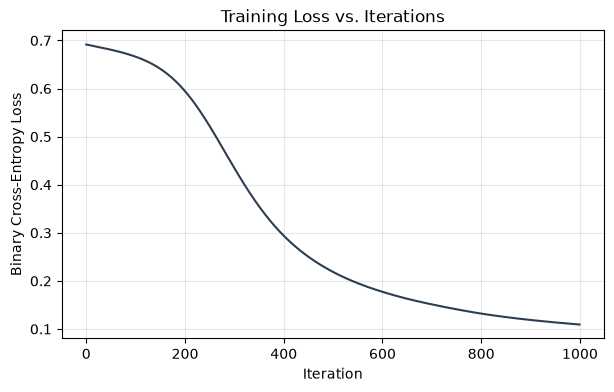

In [73]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history, color="#2c3e50")
plt.title("Training Loss vs. Iterations")
plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(alpha=0.3)
plt.show()


**What to Observe:** a healthy training run produces a curve that drops fairly quickly at first and then flattens out as the model converges. A curve that stays flat from the start may indicate the learning rate is too small or a bug in the gradient computation; a curve that spikes upward or oscillates wildly can indicate the learning rate is too large.


<a id="section15"></a>
## 15. Prediction Function

To turn the network's output probabilities into class predictions, a threshold of `0.5` is applied: probabilities above `0.5` are predicted as class `1` (benign), and probabilities at or below `0.5` are predicted as class `0` (malignant). This function reuses `forward_propagation` rather than recomputing the equations.


In [74]:
def predict(X, parameters):
    '''
    Generate binary class predictions for input X using trained parameters.

    Arguments:
    X -- input data, shape (m, n_x)
    parameters -- trained parameters (W1, b1, W2, b2)

    Returns:
    predictions -- binary predictions (0 or 1), shape (m, 1)
    '''
    probabilities, _ = forward_propagation(X, parameters)
    predictions = (probabilities > 0.5).astype(int)
    return predictions

print("predict() defined.")


predict() defined.


<a id="section16"></a>
## 16. Model Evaluation

The trained ANN is now evaluated on both the training set (to check how well it fits the data it was trained on) and the held-out test set (to check how well it generalizes to unseen data). scikit-learn is used **only** to compute evaluation metrics — the ANN itself remains entirely NumPy-based.


In [75]:
# Predictions on training and test sets
train_predictions = predict(X_train, parameters)
test_predictions = predict(X_test, parameters)

# Accuracy
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy    : {test_accuracy:.4f}")

# Confusion matrix (on test set)
cm = confusion_matrix(y_test, test_predictions)
print("\nConfusion Matrix (test set):")
print(cm)

# Classification report (on test set)
print("\nClassification Report (test set):")
print(classification_report(y_test, test_predictions, target_names=["malignant (0)", "benign (1)"]))


Training accuracy: 0.9658
Test accuracy    : 0.9825

Confusion Matrix (test set):
[[40  2]
 [ 0 72]]

Classification Report (test set):
               precision    recall  f1-score   support

malignant (0)       1.00      0.95      0.98        42
   benign (1)       0.97      1.00      0.99        72

     accuracy                           0.98       114
    macro avg       0.99      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114





**Task:** Using only the four values from the confusion matrix (`TN`, `FP`, `FN`, `TP` — printed as `cm` above, laid out as `[[TN, FP], [FN, TP]]`), manually compute **precision** and **recall** for the "benign" class, without calling any scikit-learn metric function:

$$\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}$$

Compare your manually computed values against the ones already printed in the classification report above.



In [76]:
def manual_precision_recall(cm):
    '''
    TODO: Complete this function.
    cm is a 2x2 confusion matrix laid out as [[TN, FP], [FN, TP]]
    (this matches the `cm` variable computed earlier in the notebook).
    Return a tuple (precision, recall) for the positive ("benign") class.
    '''
    # write your code here
    precision = None
    recall = None
    return precision, recall

# Once implemented, uncomment the line below to check your results
# print("Manual precision, recall:", manual_precision_recall(cm))


**What to Observe:** test accuracy should be reasonably close to training accuracy. A large gap (e.g., training accuracy near 100% while test accuracy is noticeably lower) would suggest the model has overfit to the training data rather than learning a generalizable pattern.


<a id="section17"></a>
## 17. Confusion Matrix Visualization

The confusion matrix summarizes prediction outcomes into four categories:

- **True Positive (TP)** — correctly predicted benign.
- **True Negative (TN)** — correctly predicted malignant.
- **False Positive (FP)** — predicted benign, but actually malignant.
- **False Negative (FN)** — predicted malignant, but actually benign.

In a medical context, false negatives are typically the most concerning, since they represent missed malignant cases.


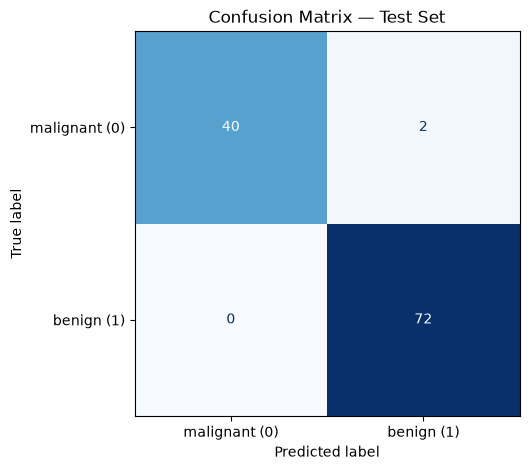

In [77]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["malignant (0)", "benign (1)"])
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix — Test Set")
plt.show()


**What to Observe:** the diagonal cells (true negatives and true positives) should contain the majority of the samples. Off-diagonal cells (false positives and false negatives) represent misclassifications — in this dataset, a false negative (predicting benign when the tumor is actually malignant) is generally the more clinically serious error type.


<a id="section20"></a>
## 20.Task :change Learning Rate

The learning rate `α` controls how large each gradient-descent step is. This experiment trains three separate ANNs — identical in every way except for the learning rate — and compares their loss curves:

- `0.001` — a small learning rate
- `0.01`  — a moderate learning rate
- `0.05`  — a larger learning rate




In [ ]:
# write code here



## Task

Using the **same manually implemented ANN** , investigate how the **size of the hidden layer** affects classification performance.

Train the network with each of the following hidden-layer sizes, keeping every other setting (learning rate, number of iterations, train/test split, random seed) unchanged:

- 8 hidden neurons
- 16 hidden neurons
- 32 hidden neurons

For **each** configuration, record:

1. Final training loss
2. Training accuracy
3. Test accuracy
4. Number of iterations used
5. A short observation about convergence behavior (e.g., speed, stability)

Then build a comparison table summarizing your results (a Pandas DataFrame is a convenient way to do this).

Finally, answer the following questions in a Markdown cell:

1. Which hidden-layer size achieved the best test accuracy?
2. Which configuration converged fastest?
3. Did increasing the hidden-layer size always improve test performance?
4. Did you observe any indication of overfitting (e.g., high training accuracy but lower test accuracy)?
5. Based on your results, which architecture would you recommend, and why?




<a id="section23"></a>
## Conclusion

In this laboratory, you implemented a complete Artificial Neural Network **entirely from first principles using NumPy**, covering:

- The architecture of a simple feed-forward ANN (input → hidden → output).
- Forward propagation using matrix operations.
- The Sigmoid and ReLU activation functions and their derivatives.
- Binary cross-entropy loss as a measure of prediction error.
- Backward propagation, applying the chain rule to compute gradients.
- Parameter updates via gradient descent.
- A full iterative training loop, monitored through a loss curve.
- Model evaluation using accuracy, a confusion matrix, and a classification report.
- The effect of hidden-layer size and learning rate on training behavior and performance.

